In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sns.set_style("whitegrid")
os.makedirs("../reports", exist_ok=True)   

df = pd.read_csv("../data/processed/cnc_clean.csv")

num_cols = ["spindle_speed_rpm", "feed_rate_mm_min", "cutting_temp_c",
            "vibration_mm_s", "tool_wear_min", "coolant_flow_lpm"]

print(df.shape)
df.head()

(2000, 9)


,part_id,material_type,spindle_speed_rpm,feed_rate_mm_min,cutting_temp_c,vibration_mm_s,tool_wear_min,coolant_flow_lpm,defect
0,1,Steel,1237.0,213.9,203.4,3.90,223.8,7.28,1
1,2,Titanium,1252.0,300.5,204.8,2.93,91.9,7.93,0
2,3,Aluminium,1432.0,126.4,166.7,3.62,175.1,10.01,0
3,4,Aluminium,1610.0,198.7,169.0,2.49,4.9,5.10,0
4,5,Steel,1774.0,225.6,190.6,2.46,49.2,8.01,0


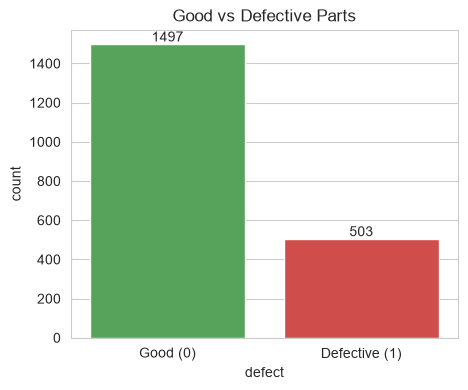

defect
0    74.9
1    25.2
Name: proportion, dtype: float64


In [7]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(x="defect", hue="defect", data=df,
                   palette=["#4CAF50", "#E53935"], legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Good (0)", "Defective (1)"])
plt.title("Good vs Defective Parts")

for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")

plt.savefig("../reports/01_target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print((df["defect"].value_counts(normalize=True) * 100).round(1))

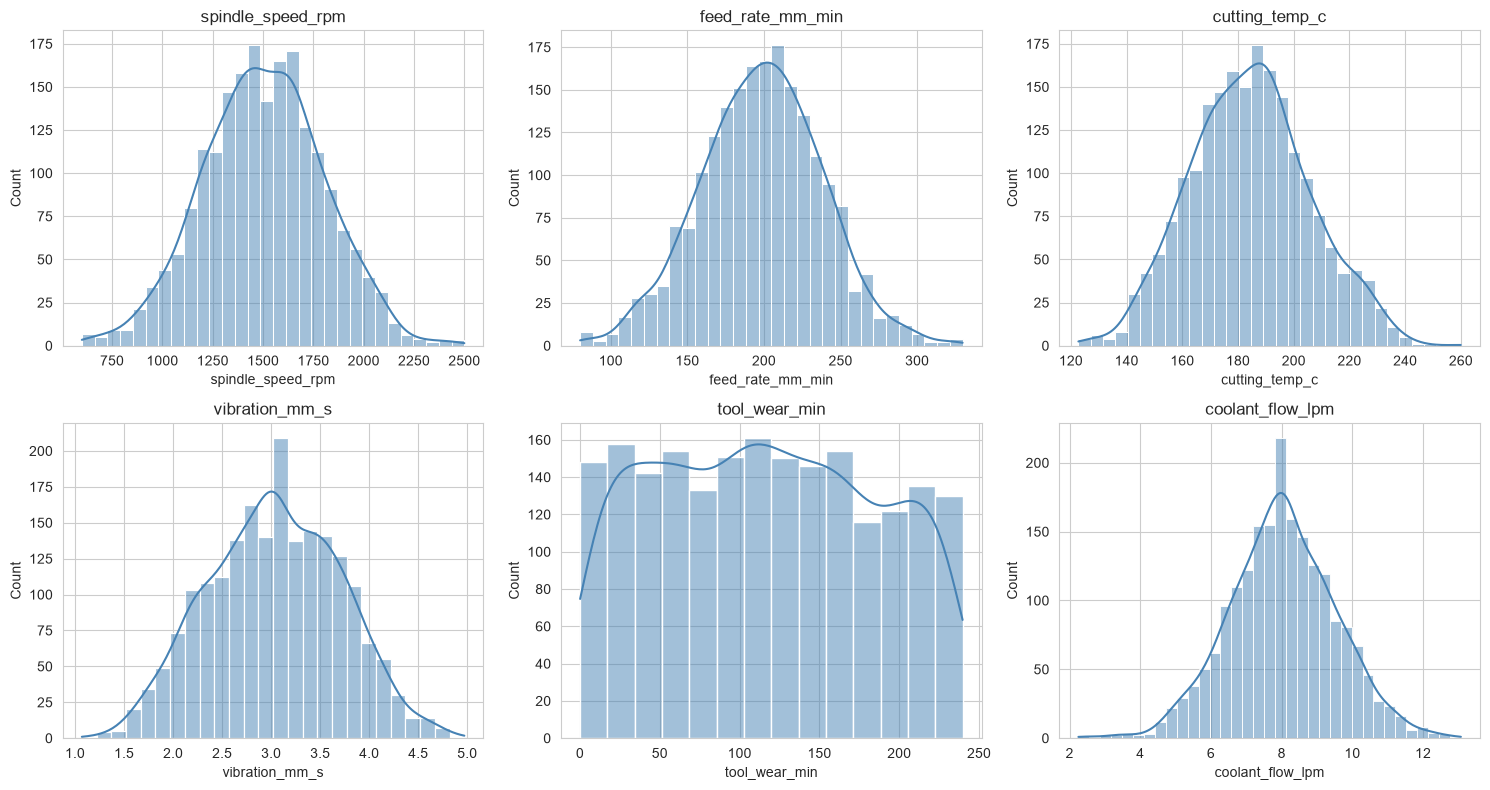

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.savefig("../reports/02_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

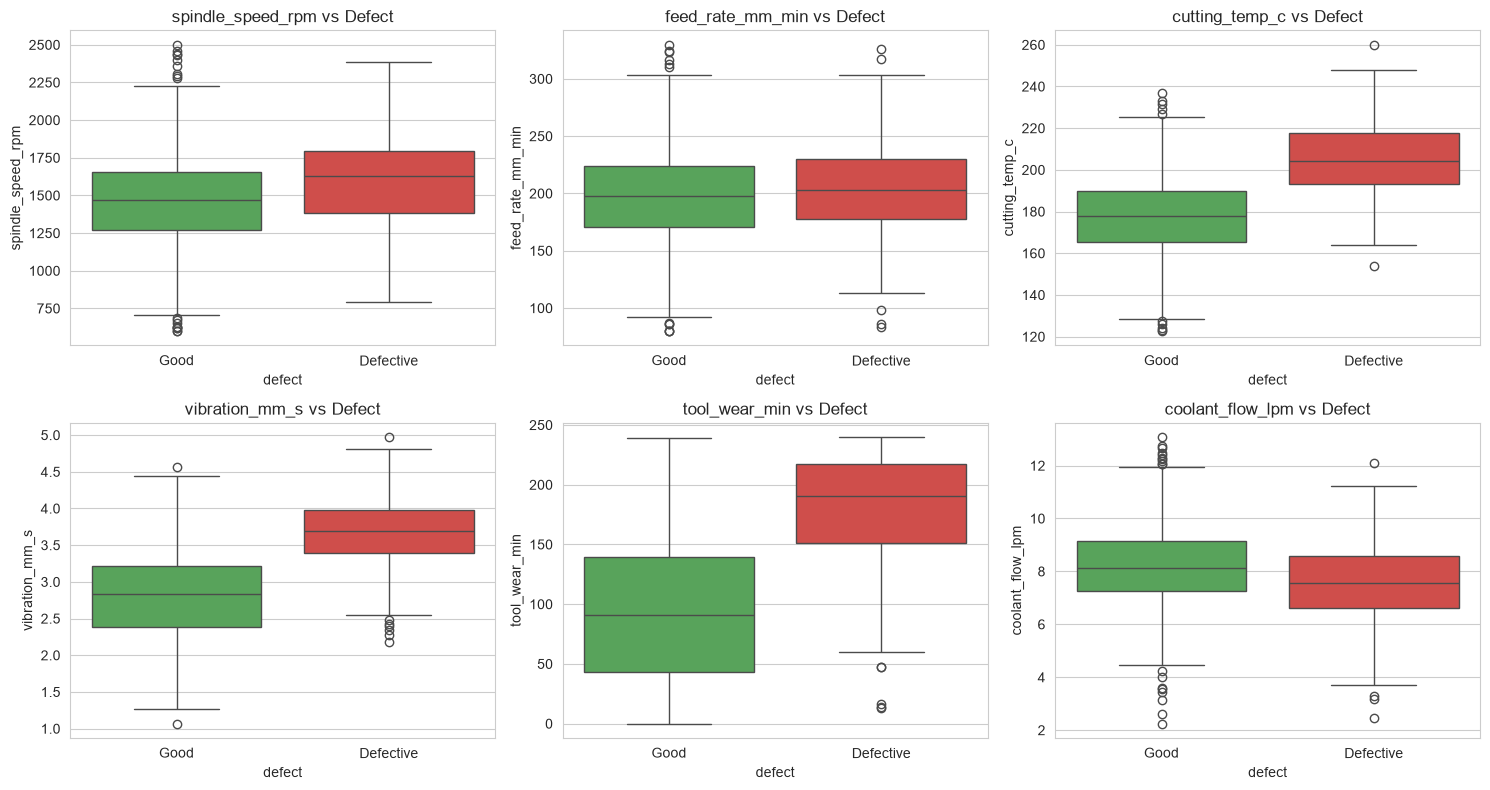

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(x="defect", y=col, hue="defect", data=df, ax=ax,
                palette=["#4CAF50", "#E53935"], legend=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Good", "Defective"])
    ax.set_title(f"{col} vs Defect")
plt.tight_layout()
plt.savefig("../reports/03_features_vs_defect.png", dpi=150, bbox_inches="tight")
plt.show()

material_type
Aluminium    14.4
Steel        25.3
Titanium     40.9
Name: defect, dtype: float64


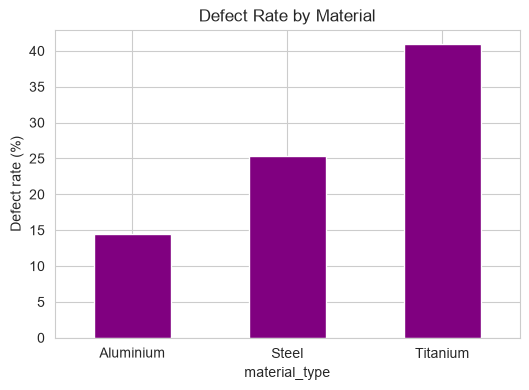

In [13]:
mat_rate = df.groupby("material_type")["defect"].mean().mul(100).round(1).sort_values()
print(mat_rate)

plt.figure(figsize=(6, 4))
mat_rate.plot(kind="bar", color="purple")
plt.ylabel("Defect rate (%)")
plt.title("Defect Rate by Material")
plt.xticks(rotation=0)
plt.savefig("../reports/04_material_defect_rate.png", dpi=150, bbox_inches="tight")
plt.show()

wear_band
0-60        1.2
60-120     10.9
120-180    31.0
180-240    63.9
Name: defect, dtype: float64


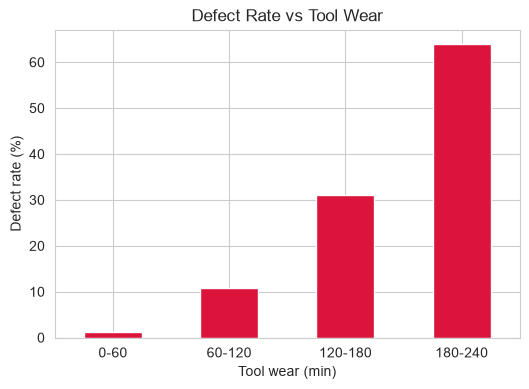

In [ ]:
df["wear_band"] = pd.cut(df["tool_wear_min"],
                         bins=[0, 60, 120, 180, 240],
                         labels=["0-60", "60-120", "120-180", "180-240"],
                         include_lowest=True)

wear_rate = df.groupby("wear_band", observed=True)["defect"].mean().mul(100).round(1)
print(wear_rate)

plt.figure(figsize=(6, 4))
wear_rate.plot(kind="bar", color="crimson")
plt.ylabel("Defect rate (%)")
plt.xlabel("Tool wear (min)")
plt.title("Defect Rate vs Tool Wear")
plt.xticks(rotation=0)
plt.savefig("../reports/05_wear_defect_rate.png", dpi=150, bbox_inches="tight")
plt.show()

df = df.drop(columns="wear_band")   

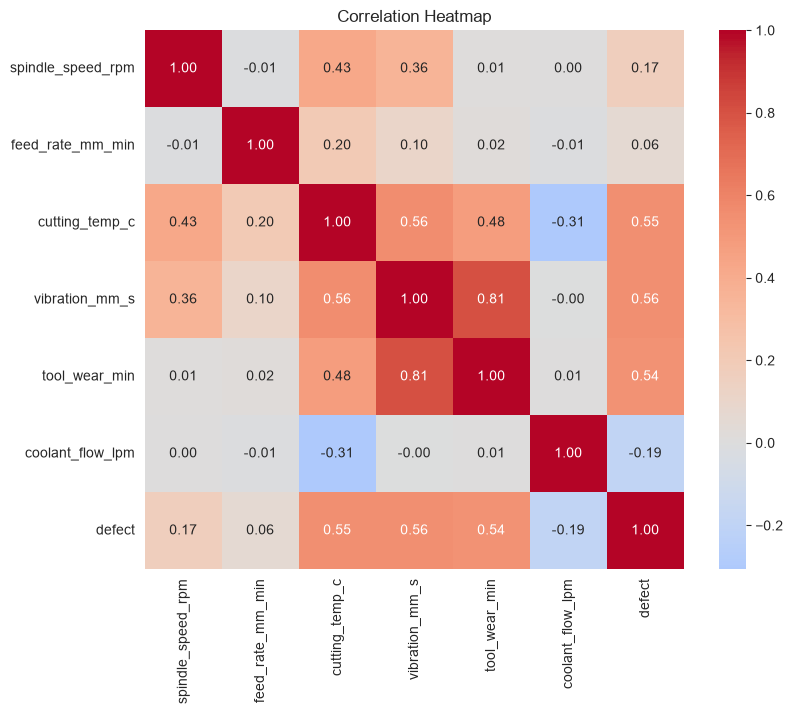

In [16]:
corr = df[num_cols + ["defect"]].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap")
plt.savefig("../reports/06_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

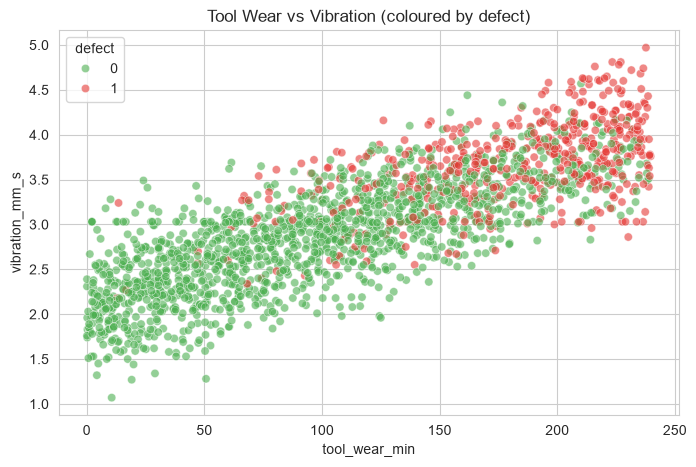

In [17]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x="tool_wear_min", y="vibration_mm_s", hue="defect",
                data=df, palette=["#4CAF50", "#E53935"], alpha=0.6)
plt.title("Tool Wear vs Vibration (coloured by defect)")
plt.savefig("../reports/07_wear_vs_vibration.png", dpi=150, bbox_inches="tight")
plt.show()

## Key Insights
1. Defective parts have higher vibration, cutting temperature and tool wear.
2. Titanium has the highest defect rate, consistent with its poor thermal conductivity.
3. Defect rate rises sharply after 180 minutes of tool usage.
4. Higher coolant flow is associated with fewer defects.
5. Data is imbalanced (25.2% defective), so accuracy alone is misleading.

## Business Recommendation
Replace tools before reaching the high-wear band, and monitor vibration in real time.